# Dynesty results — visualization

`run_dynesty.py` writes one pickle per insolation model; `load_fits` reads them back as the `{model: NestedFit}` dict every plotting helper takes. Each fit carries **its own data, priors, injected truth and `FittingConfig`**, so nothing has to be re-typed here — `logl_from_fit` rebuilds the exact likelihood the sampler used (needed by 1., 3. and 5., which still evaluate the forward model). It also checks that the forward model has not changed since the run (`check_fit_current`: the stellar grid pickled with the fit against the one the current code builds), since a fit sampled with another stellar SED, filter convention or band is not a posterior of today's likelihood.

The models need not share a parameter set: `hyperillum` and `naive` sample $(A_B, \mathrm{offset})$, `naive_redist` additionally the heat redistribution $F$ (Kreidberg & Loeb 2016, eq. 1). Everything $F$-specific — its slice, the $(A_B, F)$ map and posterior, the corner plot, the joint noiseless fit with the false-positive $F$ and the nightside temperature it implies — appears automatically when a `naive_redist` run is part of the dataset.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dynesty_utils import *
from paper_plot_utils import paper_figure, paper_theme
from dynesty import utils as dyfunc, plotting as dyplot
from dataclasses import replace
import glob, os

N_JOBS = -1      # forward models run process-parallel (loky); the plots below are the only likelihood cost
INSOL_REF = "hyperillum"   # the model the data were drawn from: always fitted, so it is the reference for the shared (A_B, offset) box and the denominator-free side of every Bayes factor
COLOR  = {"naive": "C0", "hyperillum": "C3", "naive_redist": "C2"}

In [2]:
# --- load data file ---------------------------------------------------------------------------------------
# the DATASET tag: one pattern matching EVERY model of one run, whatever each was sampled with
# (the file names end in _{insolation_model}_priors-..., so this prefix does not fix the free parameters)
RESULTS_DIR = "dynesty_results"   # where run_dynesty.py saves

# run_dynesty.py with the baseline settings (DEFAULT_A_B, DEFAULT_N_ORBITS, ... of HItargets_utils; PandExo noise from the cache), 2026-11-08
results_file = "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1_sigmascale1_seed42"

# Older datasets in "more runs/" (2026-10: blackbody star, old filter convention, A_B = 0.42, 3 orbits, old PandExo binning). They were sampled with a different forward
# model, so logl_from_fit refuses them (older FittingConfig) or warns (check_fit_current): re-run them with run_dynesty.py before analysing them here.
OLD_RESULTS = [
    # K2 141b
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min51.7_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.1_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.1_seed42",
    "K2-141b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale0.5_seed42",
    "K2-141b_MIRI-LRS_scaledA1_AB0.42_nbins27_norbits3_rms1min154.5_sigmascale1_seed42",
    # TOI 2431b
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed43",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed42",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed41",
    "TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.42_nbins27_norbits3_rms1min38.3_sigmascale1_seed40",
    "TOI-2431b_MIRI-F1280W_fixedA0.1_AB0.42_nbins27_norbits3_rms1min247.2_sigmascale1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.1_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale0.5_seed42",
    "TOI-2431b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min91.9_sigmascale1_seed42",
    # K2-157b
    "K2-157b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min1102.9_sigmascale1_seed42",
    # KOI-1843.03
    "KOI-1843.03_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min868.8_sigmascale1_seed42",
    # TOI-2260b
    "TOI-2260b_MIRI-LRS_fixedA0.1_AB0.42_nbins27_norbits3_rms1min182.0_sigmascale1_seed42",
]
# RESULTS_DIR, results_file = "more runs/OLD_before_midpoint_binning/dynesty_results", OLD_RESULTS[7]

RESULTS = f"{RESULTS_DIR}/{results_file}_*.pkl"


In [3]:
fits  = load_fits(RESULTS)                                    # {insolation_model: NestedFit}; whichever models the pattern found
fits  = {m: fits[m] for m in ("hyperillum", "naive", "naive_redist") if m in fits}   # fixed order, so colours and panels do not depend on how the files happened to sort
logls = {m: logl_from_fit(f) for m, f in fits.items()}        # the likelihood each fit was run with, rebuilt from its own cfg

# The models need NOT share a ParameterSet: only "naive_redist" samples F. Everything shared comes from the truth's own model, which is always run.
ref   = fits[INSOL_REF]
pset  = ref.pset                                               # the (A_B, offset) box every model has - what the grids below are built on
PSETS = {m: f.pset for m, f in fits.items()}                   # what each model was ACTUALLY sampled with
cfg   = ref.meta["cfg"]
data  = ref.meta["data"]
truth = data["truth"]                                          # what simulate_data injected
A_B_true, INSOL_TRUTH = truth["A_B"], truth["insolation_model"]
assert INSOL_TRUTH == INSOL_REF, f"the data were drawn from {INSOL_TRUTH}, but INSOL_REF is {INSOL_REF}"
# the injected value of every parameter ANY model samples. Only a "naive_redist" truth has an F; otherwise the data are drawn without redistribution and F = 0 is the truth for it too.
TRUTH_OF = dict(A_B=A_B_true, offset=truth["offset"], F=truth.get("F") if truth.get("F") is not None else 0.)
base  = {n: TRUTH_OF[n] for f in fits.values() for n in f.pset.names}

print(f"{cfg.planet.name}   truth = {INSOL_TRUTH}, A_B = {A_B_true:g}" + (f", F = {truth['F']:g}" if truth.get("F") is not None else "") + f", offset = {truth['offset']:g} ppm, data seed = {truth['seed']}")
print(f"{cfg.n_bins} bins over {cfg.n_orbits} orbits, rms_1min_pandexo = {cfg.sigma_1min:.1f} ppm -> sigma_bin = {cfg.sigma_bin:.1f} ppm   |   models: {', '.join(fits)}\n")
print(f"{'model':12s} {'lnZ':>20s} {'ncall':>8s} {'runtime':>9s}   status   (ESS is part of the status line)")
for m, f in fits.items():
    print(f"{m:12s} {f.meta['lnZ']:10.4f} +/- {f.meta['lnZ_err']:.4f} {f.meta['ncall']:8d} {f.meta['runtime_s']/60:7.1f} m   {f.meta['status']}")
    print(f"{'':12s} sampled: {', '.join(f.pset.names)}")
    print(f"{'':12s} {os.path.basename(f.meta.get('file', '(not saved)'))}")

TOI-2431 b   truth = hyperillum, A_B = 0.2, offset = 0 ppm, data seed = 42
27 bins over 5 orbits, rms_1min_pandexo = 39.1 ppm -> sigma_bin = 5.1 ppm   |   models: hyperillum, naive, naive_redist

model                         lnZ    ncall   runtime   status   (ESS is part of the status line)
hyperillum     -83.1800 +/- 0.0595    32364     5.3 m   CONVERGED | stop 0.999, 9/10 batches, ESS 9087
             sampled: A_B, offset
             TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1_sigmascale1_seed42_hyperillum_priors-A_B+offset.pkl
naive          -82.7570 +/- 0.0582    32548     9.2 m   CONVERGED | stop 0.989, 9/10 batches, ESS 9163
             sampled: A_B, offset
             TOI-2431b_JWST_NIRSpec.G395H_NRS1_fixedA0.1_AB0.2_nbins27_norbits5_rms1min39.1_sigmascale1_seed42_naive_priors-A_B+offset.pkl
naive_redist   -85.8685 +/- 0.0732    45885     6.9 m   CONVERGED | stop 0.939, 9/10 batches, ESS 10091
             sampled: A_B, offset, F
         

## 1. Data and Likelihood

Plotted as $\Delta\ln\mathcal{L}=\ln\mathcal{L}-\ln\mathcal{L}_{\max}$. In the slices the dotted lines at $-0.5,-2,-4.5$ are the 1-parameter $1/2/3\sigma$ levels; in the maps the contours are the 2-parameter ones ($-1.15,-3.09,-5.91$). With uniform priors $\exp(\ln\mathcal{L})$ over the box *is* the un-normalised posterior, so the maps preview the corner plots in 2.

The slices hold every other parameter at the injected truth, so in the $A_B$ and offset panels `naive_redist` (at its injected $F=0$) **is** the naive model and its dashed curve lies on top of the naive one. The $F$ slice and the $(A_B, F)$ map appear only when a `naive_redist` run is loaded; in that map the additive offset is profiled out (maximised per cell, free since it reuses the cell's forward model), because it correlates with $F$ and a fixed-offset slice would look tighter than the fit is. The $F$ axes are zoomed to where the likelihood is still on the panel, on a linear scale.


sigma_bin: 5.06 ppm  (bin width 11.96 min)
chi2 / n_bins (normalized average noise per bin ~1): 0.63
residual mean / sigma (~0): -0.03


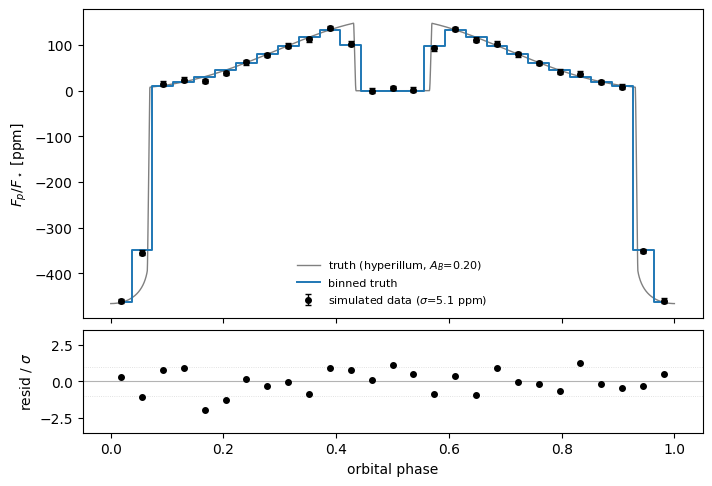

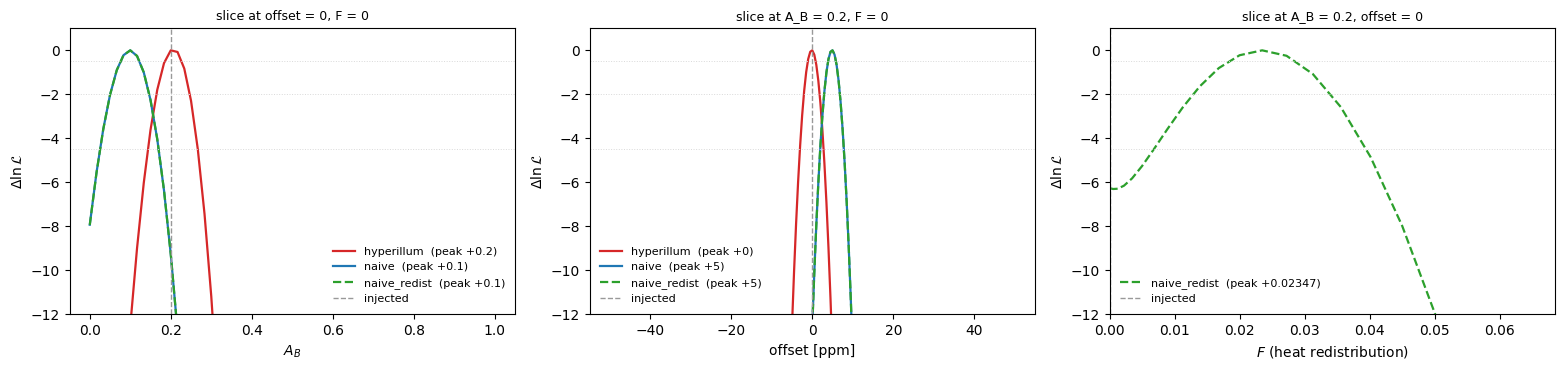

hyperillum   grid MAP: A_B = 0.2167, offset = +0.50 ppm, lnL = -77.047


naive        grid MAP: A_B = 0.1667, offset = +4.00 ppm, lnL = -76.771


naive_redist grid MAP: A_B = 0.1667, offset = +4.00 ppm, lnL = -76.771


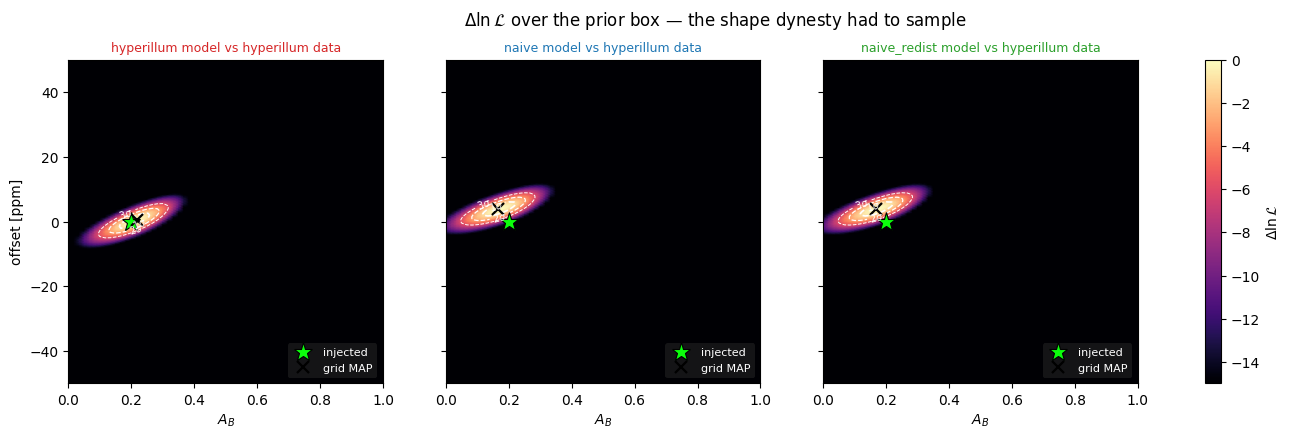

naive_redist grid MAP: A_B = 0.1500, F = 0.0091, lnL = -76.526   (offset profiled out)


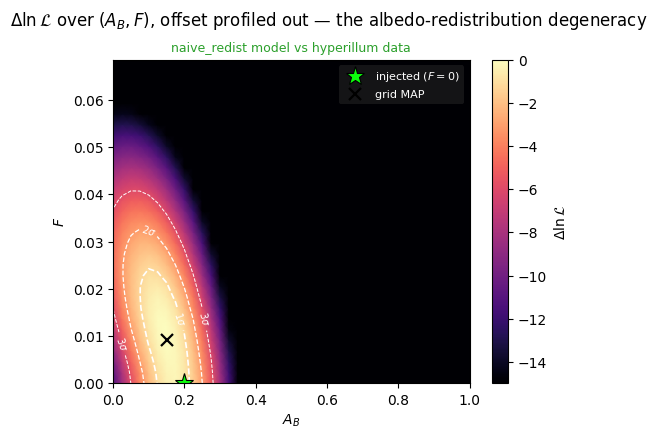

In [4]:
PAPER_MODE = False
A_grid, O_grid = pset.grid("A_B", 61),  pset.grid("offset", 201)

# the truth curve is re-evaluated here (one forward model), the data points come straight out of the saved fit
plot_simulated_data(cfg, A_B_true, data, insolation_model=INSOL_TRUTH)
paper_figure(f"dynesty_simulated_data_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, tight=False)
plt.show()

# 1D slices. One panel per parameter ANY model samples - so F gets its own as soon as a "naive_redist" run is loaded,
# and the models that do not sample it simply have no curve there.
F_MODELS = [m for m in fits if "F" in PSETS[m].names]          # [] when no redistribution run is in this dataset
GRIDS  = {"A_B": A_grid, "offset": O_grid}
if F_MODELS:   # F nodes over the full prior but quadratically dense towards 0, where the likelihood sits (the response to F is ~F^1.5 near 0 and the posterior is a sliver of the prior); the panel is zoomed below
    lo_F, hi_F = PSETS[F_MODELS[0]].bounds[PSETS[F_MODELS[0]].names.index("F")]
    GRIDS["F"] = lo_F + (hi_F - lo_F) * np.linspace(0., 1., 61) ** 2
XLABEL = {"A_B": "$A_B$", "offset": "offset [ppm]", "F": "$F$ (heat redistribution)"}
YLIM   = -12.

SLICES = {}
fig, axes = plt.subplots(1, len(GRIDS), figsize=(5.25 * len(GRIDS), 3.8), squeeze=False)
for ax, (p, g) in zip(axes.ravel(), GRIDS.items()):
    for name, L in logls.items():
        if p not in L.names: continue                          # e.g. F, which only "naive_redist" has
        s = logl_slice(L, p, g, base, n_jobs=N_JOBS)           # one forward model per node, except "offset" (additive -> free)
        SLICES[p, name] = s
        # dashed for naive_redist: at the injected F = 0 it IS the naive model, so in the A_B and offset panels the two curves lie exactly on top of each other
        ax.plot(g, s - s.max(), color=COLOR[name], lw=1.6, ls="--" if name == "naive_redist" else "-", label=f"{name}  (peak {g[s.argmax()]:+.4g})")
    for d in (-0.5, -2.0, -4.5):
        ax.axhline(d, color="0.85", lw=0.7, ls=":")
    ax.axvline(base[p], color="0.6", lw=1.0, ls="--", label="injected")
    ax.set_xlabel(XLABEL[p]); ax.set_ylabel(r"$\Delta\ln\mathcal{L}$")
    ax.set_ylim(YLIM, 1.); ax.legend(frameon=False, fontsize=8)
    ax.set_title("slice at " + ", ".join(f"{q} = {base[q]:g}" for q in GRIDS if q != p), fontsize=9)
    if p == "F":   # the F posterior is a sliver against its [0, 0.5] prior, so zoom the axis to where the curve is still on the panel (linear, never sqrt)
        on = np.concatenate([g[(SLICES[p, m] - SLICES[p, m].max()) > YLIM] for m in F_MODELS])
        F_LIM = (g[0], min(g[-1], on.max() + 0.5 * np.ptp(on) + 1e-3))   # from the prior floor F = 0 (the injected truth and the physical edge) up to where the curve leaves the panel; reused by the (A_B, F) map below
        ax.set_xlim(*F_LIM)
plt.tight_layout(); paper_figure(f"dynesty_lnL_slices_{cfg.planet.name.replace(' ', '')}", PAPER_MODE); plt.show()

# 2D map
lnL_maps = {}
for name, L in logls.items():
    lnL = logl_grid(L, "A_B", A_grid, "offset", O_grid, base, n_jobs=N_JOBS)   # (n_off, n_A_B)
    lnLmax, (off_map, A_map) = grid_max(lnL, O_grid, A_grid)                   # axis order of lnL: (offset, A_B)
    lnL_maps[name] = (lnL, lnLmax, A_map, off_map)
    print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, offset = {off_map:+.2f} ppm, lnL = {lnLmax:.3f}")

fig, axes = plt.subplots(1, len(lnL_maps), figsize=(5.75 * len(lnL_maps), 4.2), sharex=True, sharey=True, squeeze=False)
axes = axes.ravel()
for ax, (name, (lnL, lnLmax, A_map, off_map)) in zip(axes, lnL_maps.items()):
    d = lnL - lnLmax
    im = ax.pcolormesh(A_grid, O_grid, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
    cs = ax.contour(A_grid, O_grid, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
    ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
    ax.plot(A_B_true, base["offset"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected")   # not C0/C3: those now mean naive/hyperillum
    ax.plot(A_map, off_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")   # the MAP always sits in the bright peak
    ax.set_xlabel("$A_B$")
    ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
    ax.legend(loc="lower right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
axes[0].set_ylabel("offset [ppm]")
fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")   # shared: both panels use vmin=-15, vmax=0
fig.suptitle(r"$\Delta\ln\mathcal{L}$ over the prior box — the shape dynesty had to sample", y=1.0)
paper_figure(f"dynesty_lnL_maps_{cfg.planet.name.replace(' ', '')}", PAPER_MODE)
plt.show()

# 2D map over (A_B, F), the pair the whole naive_redist fit is about: how much albedo the fit trades for how much
# redistribution. The additive offset is PROFILED OUT rather than held at base (it correlates with F, so a fixed-offset
# slice looks tighter than the fit is) - free, since every offset reuses the cell's one forward model.
lnL_maps_F = {}
if F_MODELS:
    A_gridF = pset.grid("A_B", 41)
    F_gridF = np.linspace(*F_LIM, 31)   # the same zoom as the slice panel, so the two F figures are on one scale
    for name in F_MODELS:
        lnL = logl_grid(logls[name], "A_B", A_gridF, "F", F_gridF, base, n_jobs=N_JOBS, profile_offset=O_grid)   # (n_F, n_A_B)
        lnLmax, (F_map, A_map) = grid_max(lnL, F_gridF, A_gridF)                                                 # axis order of lnL: (F, A_B)
        lnL_maps_F[name] = (lnL, lnLmax, A_map, F_map)
        print(f"{name:12s} grid MAP: A_B = {A_map:.4f}, F = {F_map:.4f}, lnL = {lnLmax:.3f}   (offset profiled out)")

    fig, axes = plt.subplots(1, len(lnL_maps_F), figsize=(5.75 * len(lnL_maps_F), 4.2), sharex=True, sharey=True, squeeze=False)
    for ax, (name, (lnL, lnLmax, A_map, F_map)) in zip(axes.ravel(), lnL_maps_F.items()):
        d = lnL - lnLmax
        im = ax.pcolormesh(A_gridF, F_gridF, d, vmin=-15, vmax=0., cmap="magma", shading="gouraud")
        cs = ax.contour(A_gridF, F_gridF, d, levels=[-5.91, -3.09, -1.15], colors="w", linewidths=[0.7, 0.9, 1.2])
        ax.clabel(cs, fmt={-5.91: r"3$\sigma$", -3.09: r"2$\sigma$", -1.15: r"1$\sigma$"}, fontsize=7)
        ax.plot(A_B_true, base["F"], "*", ms=14, mfc="#0cff0c", mec="k", mew=.8, label="injected ($F=0$)")
        ax.plot(A_map, F_map, "x", ms=9, color="k", mew=1.6, label="grid MAP")
        ax.set_xlabel("$A_B$")
        ax.set_title(f"{name} model vs {INSOL_TRUTH} data", fontsize=9, color=COLOR[name])
        ax.legend(loc="upper right", fontsize=8, labelcolor="w", facecolor="0.15", edgecolor="none", framealpha=.55)
    axes.ravel()[0].set_ylabel("$F$")
    fig.colorbar(im, ax=axes, label=r"$\Delta\ln\mathcal{L}$")
    fig.suptitle(r"$\Delta\ln\mathcal{L}$ over $(A_B, F)$, offset profiled out — the albedo-redistribution degeneracy", y=1.0)
    paper_figure(f"dynesty_lnL_maps_AB_F_{cfg.planet.name.replace(' ', '')}", PAPER_MODE)
    plt.show()

## 2. Dynesty results

Posterior overlay (filled: the sampler's 68/95% credible regions from `samples_equal()`; dotted: the profile-likelihood contours from 1.), the per-parameter bias against the injected truth, and one Bayes factor per alternative model, each against the truth's own model. With a `naive_redist` run: the $(A_B, F)$ posterior against the profile-likelihood map of 1., the full corner plot, and the upper limits on $F$ — its posterior is one-sided against the $F \geq 0$ prior, so a median $\pm$ interval misdescribes it. The one-seed fits against the noiseless truth are in 4.


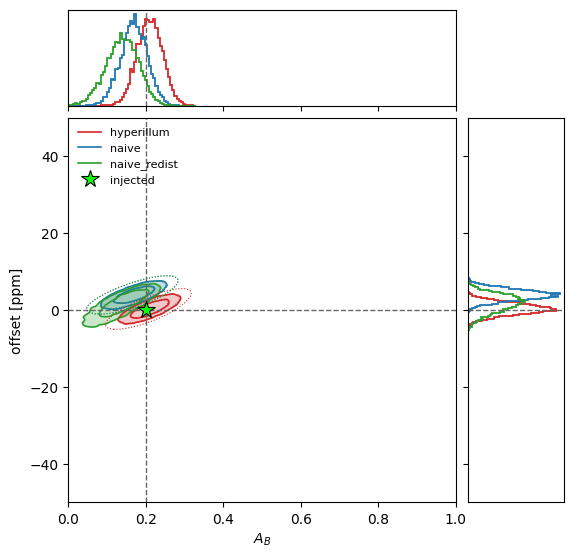

hyperillum   ESS 9087, information 5.16 nats
   A_B      =    0.2100 +0.0327 -0.0323   truth 0.2, bias +0.0100 = +0.31 sigma
   offset   =    0.2660 +1.5340 -1.5155   truth 0, bias +0.2660 = +0.17 sigma
   corr(A_B, offset) = +0.778
naive   ESS 9163, information 5.01 nats
   A_B      =    0.1699 +0.0335 -0.0350   truth 0.2, bias -0.0301 = -0.88 sigma
   offset   =    3.9232 +1.4665 -1.4562   truth 0, bias +3.9232 = +2.68 sigma
   corr(A_B, offset) = +0.747
naive_redist   ESS 10091, information 8.04 nats
   A_B      =    0.1395 +0.0409 -0.0421   truth 0.2, bias -0.0605 = -1.46 sigma
   offset   =    1.8358 +2.1283 -2.5541   truth 0, bias +1.8358 = +0.78 sigma
   F        =    0.0119 +0.0086 -0.0076   truth 0, bias +0.0119 = +1.47 sigma
   corr(A_B, offset) = +0.818
   corr(A_B, F) = -0.509
   corr(offset, F) = -0.753


ln B (hyperillum vs naive) = -0.423 +/- 0.083 (analytic) +/- 0.138 (jitter, K=200)  ->  B = 0.655
P(sign of ln B secure) = 0.000  [sampler noise only, NOT a model probability]


ln B (hyperillum vs naive_redist) = +2.688 +/- 0.094 (analytic) +/- 0.150 (jitter, K=200)  ->  B = 14.7
P(sign of ln B secure) = 1.000  [sampler noise only, NOT a model probability]


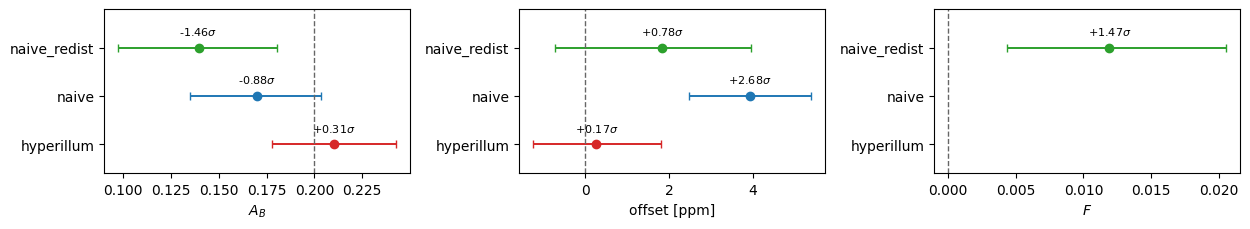

naive_redist: F < 0.0160 (68 %), F < 0.0259 (95 %)   [injected F = 0]


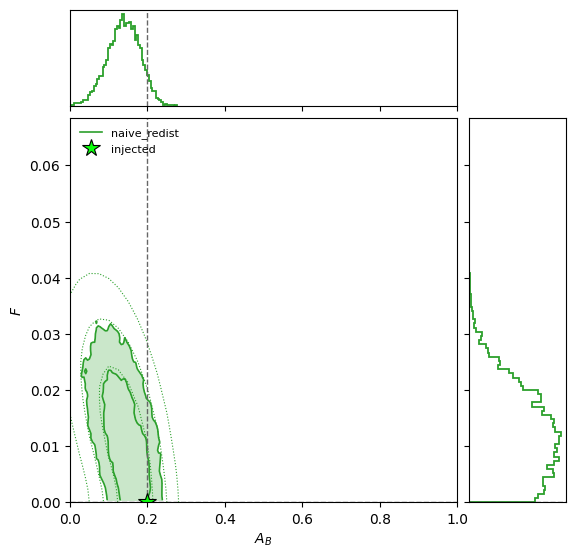

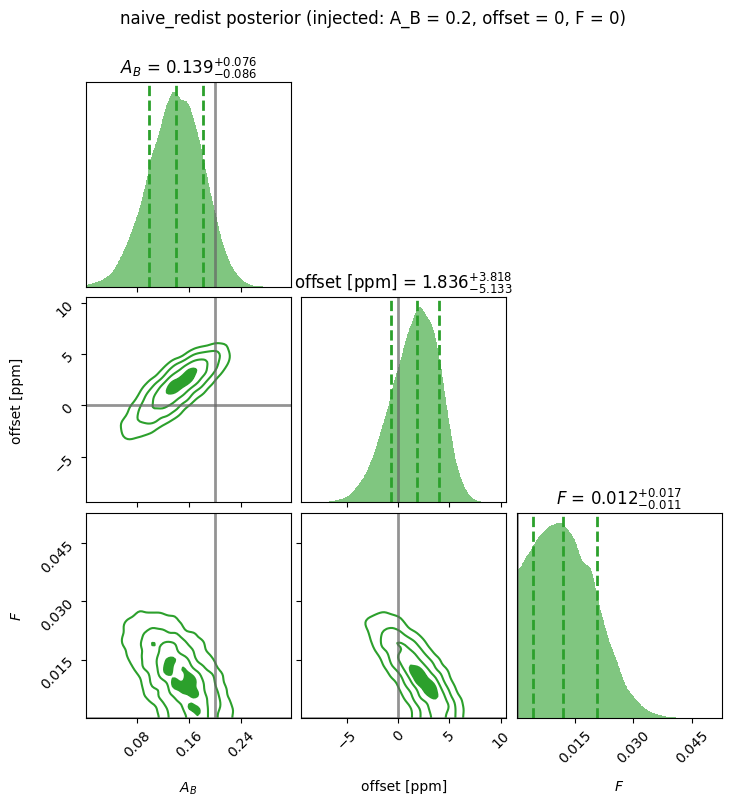

In [5]:
PAPER_MODE = False
# Posterior
profile = {name: (A_grid, O_grid, lnL) for name, (lnL, *_) in lnL_maps.items()}   # logl_grid returns (offset, A_B), which is what contour(A_grid, O_grid, ...) wants
plot_posterior_overlay(fits, "A_B", "offset", truth=base, profile=profile, colors=COLOR)
paper_figure(f"dynesty_posterior_AB_offset_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, tight=False)
plt.show()

# Bayes Factor lnB
for f in fits.values(): posterior_summary(f, base)
# one Bayes factor per alternative present, each against the truth's own model
bfs = {m: bayes_factor(fits, INSOL_REF, m, K=200) for m in fits if m != INSOL_REF}

plot_bias(fits, base, colors=COLOR); paper_figure(f"dynesty_bias_{cfg.planet.name.replace(' ', '')}", PAPER_MODE); plt.show()

# F-specific posteriors, whenever a loaded model samples it
for m in F_MODELS:   # one-sided against the F >= 0 prior: quote upper limits, not median +/- interval
    w, iF = fits[m].results.importance_weights(), PSETS[m].names.index("F")
    q68, q95 = dyfunc.quantile(fits[m].results.samples[:, iF], [0.68, 0.95], weights=w)
    print(f"{m}: F < {q68:.4f} (68 %), F < {q95:.4f} (95 %)   [injected F = {base['F']:g}]")
if F_MODELS:
    # the (A_B, F) plane: filled = the sampler's credible regions, dotted = the profile-likelihood contours of the map in 1.
    plot_posterior_overlay({m: fits[m] for m in F_MODELS}, "A_B", "F", truth=base,
                           profile={m: (A_gridF, F_gridF, lnL) for m, (lnL, *_) in lnL_maps_F.items()}, colors=COLOR)
    paper_figure(f"dynesty_posterior_AB_F_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, tight=False)
    plt.show()

    # full corner: F against every other sampled parameter, from the equal-weight posterior
    for m in F_MODELS:
        fig, _ = dyplot.cornerplot(fits[m].results, labels=list(PSETS[m].labels), color=COLOR[m],
                                   truths=[base[n] for n in PSETS[m].names], truth_color="0.4",
                                   show_titles=True, title_fmt=".3f", quantiles=(0.16, 0.5, 0.84),
                                   fig=plt.subplots(PSETS[m].ndim, PSETS[m].ndim, figsize=(2.6 * PSETS[m].ndim,) * 2))
        fig.suptitle(f"{m} posterior (injected: " + ", ".join(f"{n} = {base[n]:g}" for n in PSETS[m].names) + ")", y=1.04)
        paper_figure(f"dynesty_corner_{m}_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, tight=False)
        plt.show()

## 3. Posterior predictive — and where in phase the evidence comes from

Bottom panel (the `num` - `den` pair only; every model is still in the two panels above): the difference of the two median curves against $\pm\sigma_{\rm bin}$, plus the per-bin $\Delta\chi^2$ between the two **best-fit** (max-$\ln\mathcal{L}$) models. Those bars sum to $2\,\Delta\ln\mathcal{L}_{\max}$, so they attribute the evidence to specific orbital phases. One figure per alternative model, each against the truth's own model (the same pairs as the Bayes factors in 2.).

Costs `N_DRAWS` forward models per insolation model and figure.


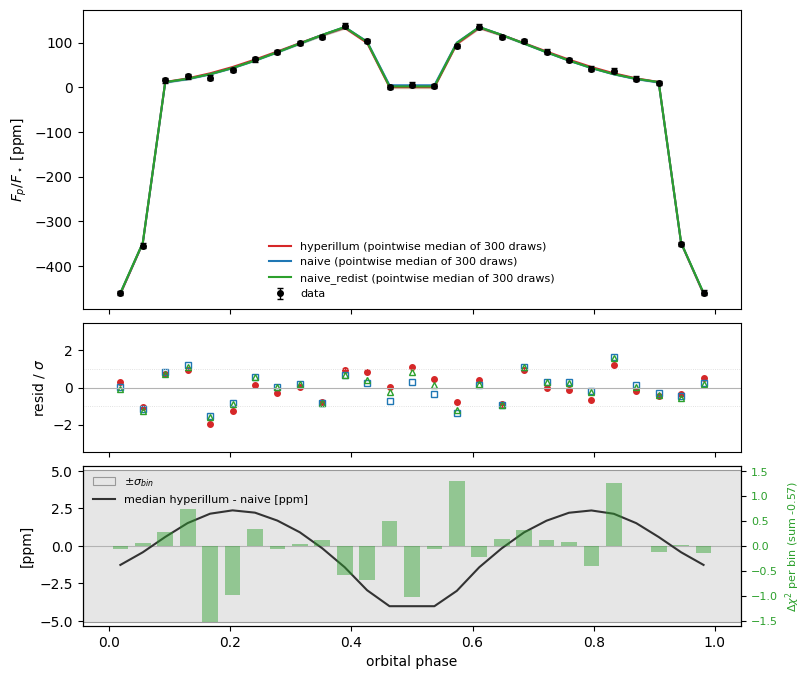

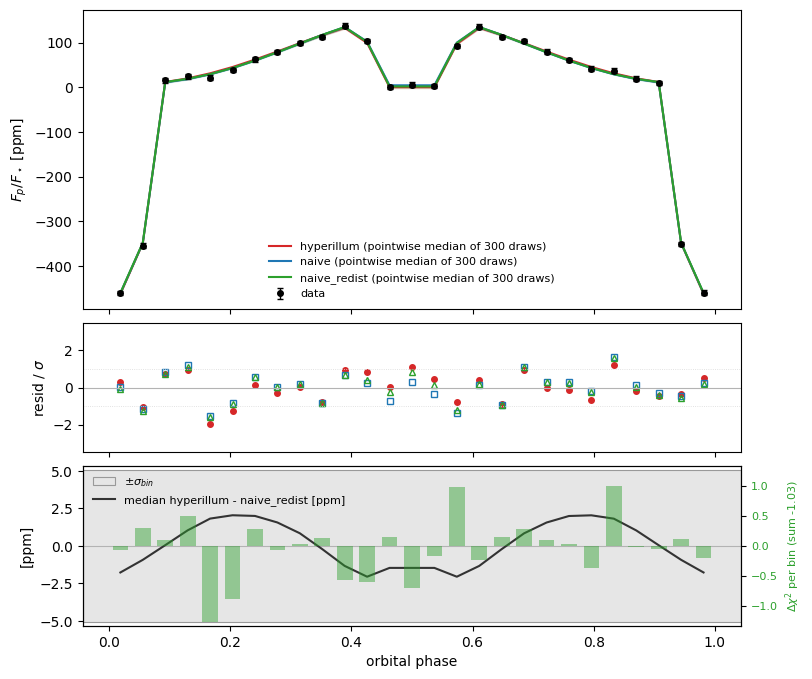

In [6]:
PAPER_MODE = False
N_DRAWS = 300   # forward models per insolation model

for den in [m for m in fits if m != INSOL_REF]:   # panel 3 is pairwise: one figure per alternative, each against the truth's own model
    plot_posterior_predictive(logls, fits, num=INSOL_REF, den=den, n=N_DRAWS, colors=COLOR, n_jobs=N_JOBS)
    paper_figure(f"dynesty_posterior_predictive_{den}_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, tight=False); plt.show() # per-bin Δχ², computed as [(y−best_a)² − (y−best_b)²]/σ², so a bar is positive where model b fits that bin better.


## 4. Bias analysis

The one-seed fits against the noiseless truth: what this dataset would make you report (the posterior medians) against the bias itself — the misspecified model fitted to the **noiseless** binned truth with the least-squares fits of the bias analysis (`simple_bias_analysis.fit_naive` for `naive`, the joint `fit_redist` in $(A_B, F)$ for `naive_redist`; offset free, no seed). For `naive_redist` the fitted $F$ is the false-positive redistribution the point-source model needs to mimic hyperillumination, and the nightside temperature it implies is printed. The bias is quoted in units of this seed's posterior width and of the Fisher $\sigma$ of the bias analysis; the two agree where the posterior is Gaussian and not truncated by the prior ($A_B \geq 0$, $F \geq 0$).

Lower panel: everything minus the binned truth, against $\pm\sigma_{\rm bin}$. Black points are the data, i.e. the noise the medians are chasing. The dotted grey line is the numerical floor — the *same* model at the *same* parameters, evaluated on the likelihood's coarser grid instead of the truth's. It should sit on zero; whatever it does is grid resolution, not physics, and the printed bias/floor ratio is the gate on every bias number of this figure.


NOISELESS fit(s) to the NOISELESS truth  (offset free, no noise, no seed - this is THE bias; the least-squares fits of the bias analysis):
   naive        A_B 0.1619   bias -0.0381 = -1.11 sigma_A_B (posterior, this seed) = -1.10 sigma_Fisher   ->   dT_sub/T = +1.17 %
                |dA_B|/sigma_A_B = 1.11   ->   sigma_1min,crit = 43.6 ppm/min (posterior) / 43.2 ppm/min (Fisher)   (now 39.1, already finer: the bias is a 1.1 sigma effect at the delivered noise)
                bias / floor = 4.524 / 0.001 = 5492.7x   ->   bias resolved
   naive_redist A_B 0.1071   bias -0.0929 = -2.24 sigma_A_B (posterior, this seed) = -1.95 sigma_Fisher   ->   dT_sub/T = +2.02 %
                F   0.0195   false positive (truth F = 0) = 2.41 sigma_F (posterior), sigma_F,Fisher = 0.0089 (one-sided at F = 0: indicative only)   ->   implied nightside T = 871 K
                |dA_B|/sigma_A_B = 2.24   ->   sigma_1min,crit = 87.6 ppm/min (posterior) / 76.1 ppm/min (Fisher)   (now 39.1, already finer: the

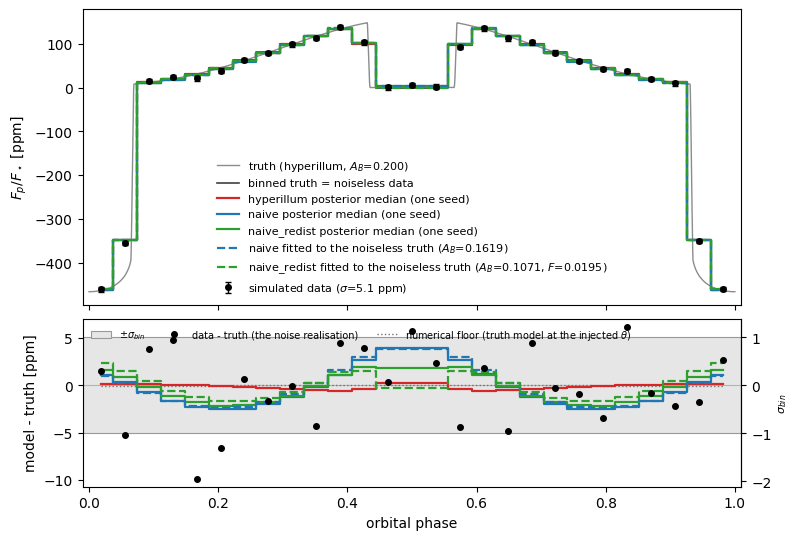

In [7]:
PAPER_MODE = False
fig, (ax, axr), out = plot_noisy_vs_truth(cfg, data, logls, fits, A_B_true, base, insolation_truth=INSOL_TRUTH,
                                          colors=COLOR)   # the noiseless naive fit (the bias) in A_B_FIT_BOUNDS, as in the bias analysis
paper_figure(f"dynesty_noisy_vs_truth_{cfg.planet.name.replace(' ', '')}", PAPER_MODE, fig=fig, tight=False)
plt.show()

## 5. Derived quantities

The posterior pushed through to physics, each model through **its own** temperature map - i.e. what you would infer if you believed that model: the substellar, terminator and antistellar (nightside) temperatures, the occultation depth and the dayside brightness temperature.
`T_term` > 0 for naive is an interpolation artefact: it is `np.interp` of the temperature grid at exactly 90°, between the last dayside and the first nightside node. The naive and hyperillum nightsides (`T_anti`) are exactly 0 K (drawn as lines, not histograms); under `naive_redist` it is the redistributed nightside $T^4 \propto (1-A_B)\,F\,S/2$ — the nightside temperature an observer would infer from a model that is free to redistribute heat, against a truth with none.


hyperillum   occultation_depth  151.27 ppm
naive        occultation_depth  148.77 ppm


naive_redist occultation_depth  148.77 ppm


hyperillum   depth  157.1 +3.0 -4.0 ppm (thermal 150.8, reflected 6.3)   T_bright 2381.5 +21.7 -28.8 K
             T_sub 2704.3 K   T_term 1510.7 K   T_anti    0.0 K
naive        depth  157.8 +3.1 -3.5 ppm (thermal 151.6, reflected 6.2)   T_bright 2387.2 +22.2 -25.3 K
             T_sub 2718.0 K   T_term  548.8 K   T_anti    0.0 K
naive_redist depth  159.9 +3.6 -4.1 ppm (thermal 153.7, reflected 6.2)   T_bright 2402.7 +26.1 -29.6 K
             T_sub 2731.8 K   T_term  860.3 K   T_anti  761.8 K +109.8 -156.1 (< 943 K at 95 %)


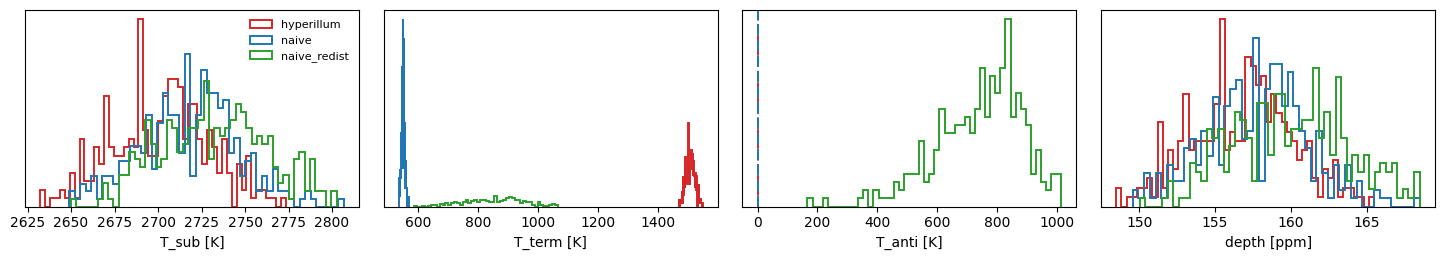

In [8]:
PAPER_MODE = False
# Check on the factored-out pcurve_params: for a thermal-only, transit-free config the occultation depth must match the peak of the phase curve model_pcurve builds from the same sp.ModelParams.
cfg_th = replace(cfg, reflected=False, transit=False)
for m in fits:
    F_ = base["F"] if "F" in PSETS[m].names else None   # only "naive_redist" has one, and at the injected truth it is 0
    _, y_ = model_pcurve(cfg_th, m, A_B_true, F=F_, n_t=200 * cfg.n_bins)
    d_ = occultation_depth(pcurve_params(cfg_th, m, A_B_true, F=F_), stellar_grid=cfg.stellar_grid, emissivity=cfg_th.emissivity)
    print(f"{m:12s} occultation_depth {d_:7.2f} ppm")

der = {m: derived_samples(logls[m], equal_samples(fits[m], N_DRAWS, seed=0), n_jobs=N_JOBS) for m in fits}
for name, d in der.items():
    q, q_th = np.percentile(d["depth"], [16, 50, 84]), np.percentile(d["depth_th"], [16, 50, 84])
    Tb = brightness_temperature(d["depth_th"], cfg)
    print(f"{name:12s} depth {q[1]:6.1f} +{q[2]-q[1]:.1f} -{q[1]-q[0]:.1f} ppm (thermal {q_th[1]:.1f}, reflected {np.median(d['depth_refl']):.1f})   T_bright {Tb[1]:6.1f} +{Tb[2]-Tb[1]:.1f} -{Tb[1]-Tb[0]:.1f} K")
    Ta = np.percentile(d["T_anti"], [16, 50, 84, 95])
    print(f"{'':12s} T_sub {np.median(d['T_sub']):6.1f} K   T_term {np.median(d['T_term']):6.1f} K   T_anti {Ta[1]:6.1f} K" + (f" +{Ta[2]-Ta[1]:.1f} -{Ta[1]-Ta[0]:.1f} (< {Ta[3]:.0f} K at 95 %)" if name in F_MODELS else ""))

KEYS = ("T_sub", "T_term", "T_anti", "depth") if F_MODELS else ("T_sub", "T_term", "depth")   # the nightside only becomes a distribution with a redistributing model
plot_derived(der, keys=KEYS, colors=COLOR); paper_figure(f"dynesty_derived_{cfg.planet.name.replace(' ', '')}", PAPER_MODE); plt.show()